YOLO PRUNNER L2 NORM BASED

In [ ]:
# helper functions and classes for pruning YOLOv8 models using torch-pruning
import argparse
import math
import os
from copy import deepcopy
from datetime import datetime
from pathlib import Path
from typing import List, Union

import numpy as np
import torch
import torch.nn as nn
from matplotlib import pyplot as plt
from ultralytics import YOLO, __version__
from ultralytics.nn.modules import Detect, C2f, Conv, Bottleneck
from ultralytics.engine.trainer import BaseTrainer
from ultralytics.utils import YAML, LOGGER, RANK, DEFAULT_CFG_DICT, DEFAULT_CFG_KEYS
from ultralytics.utils.checks import check_yaml
from ultralytics.utils.torch_utils import initialize_weights

import torch_pruning as tp

print("✅ All imports successful!")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"torch_pruning version: {tp.__version__}")


def patch_torch_load_for_pytorch26():
    """Patch torch.load to work with PyTorch 2.6+ security changes"""
    original_load = torch.load
    
    def patched_load(f, map_location=None, weights_only=None, **kwargs):
        try:
            return original_load(f, map_location=map_location, weights_only=False, **kwargs)
        except Exception as e:
            return original_load(f, map_location=map_location, weights_only=weights_only, **kwargs)
    
    torch.load = patched_load
    print("✅ torch.load patched for PyTorch 2.6+ compatibility")

patch_torch_load_for_pytorch26()


# ========================================
# HELPER FUNCTIONS
# ========================================

def de_parallel(model):
    """Remove DataParallel wrapper if present"""
    return model.module if isinstance(model, nn.DataParallel) else model


def attempt_load_one_weight(model_path, device='cpu'):
    """Load model with compatibility for different ultralytics versions"""
    try:
        from ultralytics import YOLO as YOLOModel
        model = YOLOModel(model_path)
        return model.model, None
    except Exception as e:
        print(f"❌ Could not load model: {e}")
        return None, None


def ensure_loss_device_compatibility():
    """Ensure Ultralytics v8DetectionLoss proj tensor is on the correct device."""
    try:
        from ultralytics.utils.loss import v8DetectionLoss
    except Exception:
        return

    if getattr(v8DetectionLoss, "_device_compatibility_wrapped", False):
        return

    orig_bbox_decode = v8DetectionLoss.bbox_decode

    def bbox_decode_fixed(self, anchor_points, pred_dist):
        if hasattr(self, 'proj') and isinstance(self.proj, torch.Tensor):
            if self.proj.device != pred_dist.device:
                self.proj = self.proj.to(pred_dist.device)
        return orig_bbox_decode(self, anchor_points, pred_dist)

    v8DetectionLoss.bbox_decode = bbox_decode_fixed
    v8DetectionLoss._device_compatibility_wrapped = True


def save_pruning_performance_graph(x, y1, y11, y2, pruning_method="L2"):
    """Draw performance change graph"""
    try:
        plt.style.use("ggplot")
    except:
        pass

    x, y1, y11, y2 = np.array(x), np.array(y1), np.array(y11), np.array(y2)
    y2_ratio = y2 / y2[0]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.set_xlabel('Pruning Ratio (%)')
    ax.set_ylabel('mAP')
    ax.plot(x, y1, label='recovered mAP', marker='o')
    ax.plot(x, y11, color='tab:blue', label='recovered mAP50', marker='s')

    ax2 = ax.twinx()
    ax2.set_ylabel('MACs Ratio')
    ax2.plot(x, y2_ratio, color='tab:orange', label='MACs', marker='^')

    lines, labels = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax2.legend(lines + lines2, labels + labels2, loc='best')

    ax.set_xlim(105, 20)
    ax.set_ylim(0, max(y11) + 0.05)
    ax2.set_ylim(0.05, 1.05)

    max_y1_idx = np.argmax(y1)
    max_y11_idx = np.argmax(y11)

    ax.text(x[max_y1_idx], y1[max_y1_idx] + 0.02, f'max mAP = {y1[max_y1_idx]:.3f}', fontsize=10)
    ax.text(x[max_y11_idx], y11[max_y11_idx] + 0.02, f'max mAP50 = {y11[max_y11_idx]:.3f}', fontsize=10)

    plt.title('mAP / mAP50 and MACs vs Pruning Ratio')
    os.makedirs('results', exist_ok=True)
    plt.savefig(f'results/pruning_perf_change_{pruning_method}.png', dpi=150, bbox_inches='tight')
    print(f"✅ Performance graph saved: results/pruning_perf_change_{pruning_method}.png")


def infer_shortcut(bottleneck):
    c1 = bottleneck.cv1.conv.in_channels
    c2 = bottleneck.cv2.conv.out_channels
    return c1 == c2 and hasattr(bottleneck, 'add') and bottleneck.add


print("✅ Helper functions defined!")


class C2f_v2(nn.Module):
    """CSP Bottleneck with 2 convolutions - Modified for pruning"""
    def __init__(self, c1, c2, n=1, shortcut=False, g=1, e=0.5):
        super().__init__()
        self.c = int(c2 * e)
        self.cv0 = Conv(c1, self.c, 1, 1)
        self.cv1 = Conv(c1, self.c, 1, 1)
        self.cv2 = Conv((2 + n) * self.c, c2, 1)
        self.m = nn.ModuleList(Bottleneck(self.c, self.c, shortcut, g, k=((3, 3), (3, 3)), e=1.0) for _ in range(n))

    def forward(self, x):
        y = [self.cv0(x), self.cv1(x)]
        y.extend(m(y[-1]) for m in self.m)
        return self.cv2(torch.cat(y, 1))


def transfer_weights(c2f, c2f_v2):
    """Transfer weights from C2f to C2f_v2"""
    c2f_v2.cv2 = c2f.cv2
    c2f_v2.m = c2f.m

    state_dict = c2f.state_dict()
    state_dict_v2 = c2f_v2.state_dict()

    old_weight = state_dict['cv1.conv.weight']
    half_channels = old_weight.shape[0] // 2
    state_dict_v2['cv0.conv.weight'] = old_weight[:half_channels]
    state_dict_v2['cv1.conv.weight'] = old_weight[half_channels:]

    for bn_key in ['weight', 'bias', 'running_mean', 'running_var']:
        old_bn = state_dict[f'cv1.bn.{bn_key}']
        state_dict_v2[f'cv0.bn.{bn_key}'] = old_bn[:half_channels]
        state_dict_v2[f'cv1.bn.{bn_key}'] = old_bn[half_channels:]

    for key in state_dict:
        if not key.startswith('cv1.'):
            state_dict_v2[key] = state_dict[key]

    for attr_name in dir(c2f):
        attr_value = getattr(c2f, attr_name)
        if not callable(attr_value) and '_' not in attr_name:
            setattr(c2f_v2, attr_name, attr_value)

    c2f_v2.load_state_dict(state_dict_v2)


def replace_c2f_with_c2f_v2(module):
    """Replace all C2f modules with C2f_v2"""
    for name, child_module in module.named_children():
        if isinstance(child_module, C2f):
            shortcut = infer_shortcut(child_module.m[0])
            c2f_v2 = C2f_v2(child_module.cv1.conv.in_channels, child_module.cv2.conv.out_channels,
                            n=len(child_module.m), shortcut=shortcut,
                            g=child_module.m[0].cv2.conv.groups,
                            e=child_module.c / child_module.cv2.conv.out_channels)
            transfer_weights(child_module, c2f_v2)
            setattr(module, name, c2f_v2)
        else:
            replace_c2f_with_c2f_v2(child_module)


print("C2f_v2 module defined")


def save_model_v2(self: BaseTrainer):
    """Disabled half precision saving"""
    ckpt = {
        'epoch': self.epoch,
        'best_fitness': self.best_fitness,
        'model': deepcopy(de_parallel(self.model)),
        'ema': deepcopy(self.ema.ema),
        'updates': self.ema.updates,
        'optimizer': self.optimizer.state_dict(),
        'train_args': vars(self.args),
        'date': datetime.now().isoformat(),
        'version': __version__}

    torch.save(ckpt, self.last)
    if self.best_fitness == self.fitness:
        torch.save(ckpt, self.best)
    if (self.epoch > 0) and (self.save_period > 0) and (self.epoch % self.save_period == 0):
        torch.save(ckpt, self.wdir / f'epoch{self.epoch}.pt')
    del ckpt


def final_eval_v2(self: BaseTrainer):
    """Modified final evaluation"""
    for f in self.last, self.best:
        if f.exists():
            strip_optimizer_v2(f)
            if f is self.best:
                LOGGER.info(f'\nValidating {f}...')
                self.metrics = self.validator(model=f)
                self.metrics.pop('fitness', None)
                self.run_callbacks('on_fit_epoch_end')


def strip_optimizer_v2(f: Union[str, Path] = 'best.pt', s: str = '') -> None:
    """Strip optimizer from checkpoint"""
    x = torch.load(f, map_location=torch.device('cpu'))
    args = {**DEFAULT_CFG_DICT, **x['train_args']}
    if x.get('ema'):
        x['model'] = x['ema']
    for k in 'optimizer', 'ema', 'updates':
        x[k] = None
    for p in x['model'].parameters():
        p.requires_grad = False
    x['train_args'] = {k: v for k, v in args.items() if k in DEFAULT_CFG_KEYS}
    torch.save(x, s or f)
    mb = os.path.getsize(s or f) / 1E6
    LOGGER.info(f"Optimizer stripped from {f}, {mb:.1f}MB")


def train_v2(self: YOLO, pruning=False, **kwargs):
    """Modified training function for pruning"""
    self._check_is_pytorch_model()
    overrides = self.overrides.copy()
    overrides.update(kwargs)
    if kwargs.get('cfg'):
        LOGGER.info(f"cfg file passed. Overriding default params with {kwargs['cfg']}.")
        overrides = YAML.load(check_yaml(kwargs['cfg']))
    overrides['mode'] = 'train'
    if not overrides.get('data'):
        raise AttributeError("Dataset required but missing, i.e. pass 'data=coco128.yaml'")
    if overrides.get('resume'):
        overrides['resume'] = self.ckpt_path

    self.task = overrides.get('task') or self.task
    self.trainer = self.task_map[self.task]['trainer'](overrides=overrides, _callbacks=self.callbacks)

    if not pruning:
        if not overrides.get('resume'):
            self.trainer.model = self.trainer.get_model(weights=self.model if self.ckpt else None, cfg=self.model.yaml)
            self.model = self.trainer.model
    else:
        self.trainer.pruning = True
        self.trainer.model = self.model
        self.trainer.save_model = save_model_v2.__get__(self.trainer)
        self.trainer.final_eval = final_eval_v2.__get__(self.trainer)

    ensure_loss_device_compatibility()
    self.trainer.hub_session = self.session
    self.trainer.train()
    
    if RANK in (-1, 0):
        try:
            active_device = next(self.model.parameters()).device
        except Exception:
            active_device = None
        loaded_model, _ = attempt_load_one_weight(str(self.trainer.best), device=active_device)
        if loaded_model is not None:
            self.model = loaded_model
        self.overrides = self.model.args
        self.metrics = getattr(self.trainer.validator, 'metrics', None)


print(" Training override functions defined!")

c:\Users\alijo\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✅ All imports successful!
PyTorch: 2.6.0+cu124
CUDA available: True
torch_pruning version: 1.6.0
✅ torch.load patched for PyTorch 2.6+ compatibility
✅ Helper functions defined!
✅ C2f_v2 module defined!
✅ Training override functions defined!


PRUNING CONFIGURATION
Model: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt
Data: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml
Iterative steps: 1
Target prune rate: 60.0%
Per-step ratio: 0.6000 (60.00%)
Max mAP drop: 1
Fine-tune epochs: 100
Device: 0
✅ Model found
✅ Data YAML found
LOADING MODEL
✅ Model loaded on cuda:0

Replacing C2f with C2f_v2...
✅ C2f modules replaced with C2f_v2

📊 Baseline Model:
  MACs: 4.071 G
  Parameters: 3,011,043 (3.01 M)
BASELINE VALIDATION
Ultralytics 8.3.223  Python-3.10.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 81 layers, 3,005,843 parameters, 12,691 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.0 ms, read: 57.16.1 MB/s, size: 54.4 KB)
val: Scanning C:\Users\alijo\OneDrive\Desktop\LeafminerOnly\val\labels.cache... 314 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 314/314  0.0s
WARNING Box and s

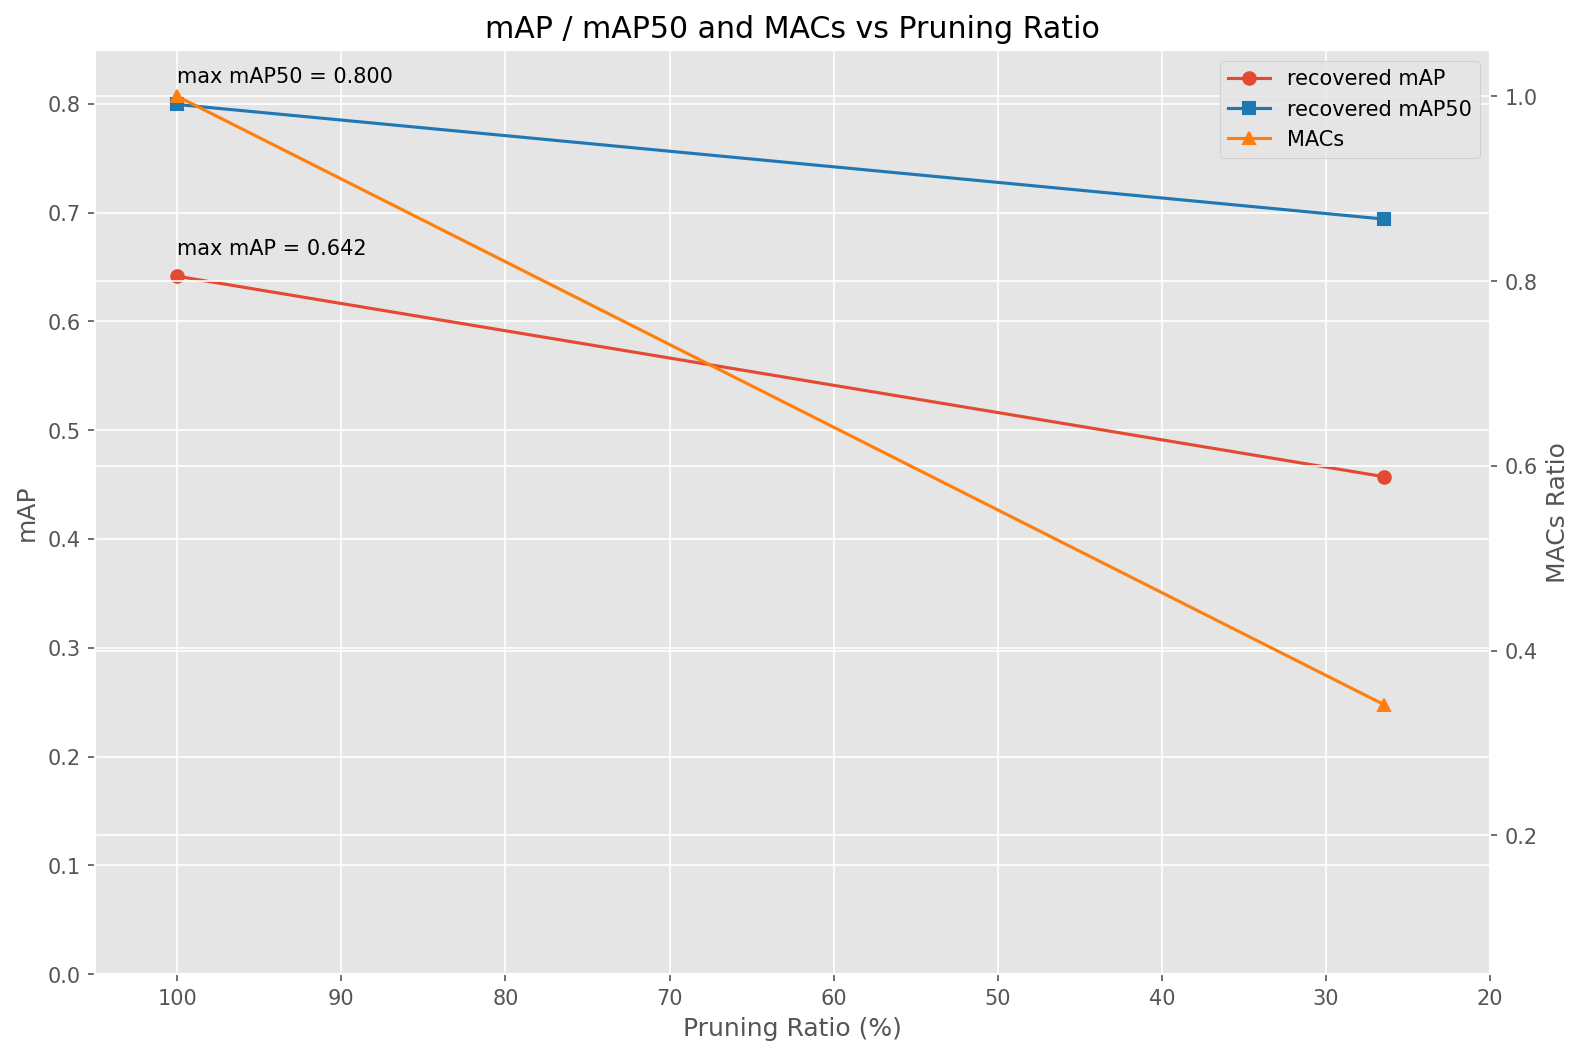

EXPORTING FINAL PRUNED MODEL

🎉 ALL DONE!


In [ ]:
#configuration
MODEL_PATH = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt"
DATA_YAML = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml"
ITERATIVE_STEPS = 1
TARGET_PRUNE_RATE = 0.60
MAX_MAP_DROP = 1

# Pruning config
pruning_cfg = {
    'data': DATA_YAML,
    'epochs': 100, 
    'batch': 16,
    'imgsz': 640,
    'device': 0 if torch.cuda.is_available() else 'cpu',
    'project': 'YOLO_V8_0.60_prune_ONE_SHOT',
    'exist_ok': True,
    'patience': 40,
    'save': True,
    'verbose': True,
    'plots': True,
    'name' : 'ONE_SHOT_PRUNNING'
}

# Calculate per-step pruning ratio
pruning_ratio = 1 - math.pow((1 - TARGET_PRUNE_RATE), 1 / ITERATIVE_STEPS)

print("="*70)
print("PRUNING CONFIGURATION")
print("="*70)
print(f"Model: {MODEL_PATH}")
print(f"Data: {DATA_YAML}")
print(f"Iterative steps: {ITERATIVE_STEPS}")
print(f"Target prune rate: {TARGET_PRUNE_RATE*100}%")
print(f"Per-step ratio: {pruning_ratio:.4f} ({pruning_ratio*100:.2f}%)")
print(f"Max mAP drop: {MAX_MAP_DROP}")
print(f"Fine-tune epochs: {pruning_cfg['epochs']}")
print(f"Device: {pruning_cfg['device']}")
print("="*70)



model = YOLO(MODEL_PATH)
model.__setattr__("train_v2", train_v2.__get__(model))
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
pruning_cfg['device'] = 0 if device.type == 'cuda' else 'cpu'
model.model.to(device)
model.model.train()

print(f"✅ Model loaded on {device}")
print("\nReplacing C2f with C2f_v2...")
replace_c2f_with_c2f_v2(model.model)
initialize_weights(model.model)
model.model.to(device)

print("✅ C2f modules replaced with C2f_v2")


for name, param in model.model.named_parameters():
    param.requires_grad = True

example_inputs = torch.randn(1, 3, pruning_cfg["imgsz"], pruning_cfg["imgsz"]).to(device)


model.model = model.model.to(device)
for param in model.model.parameters():
    param.data = param.data.to(device)

base_macs, base_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
print(f"\n📊 Baseline Model:")
print(f"  MACs: {base_macs/1e9:.3f} G")
print(f"  Parameters: {base_nparams:,} ({base_nparams/1e6:.2f} M)")


print("="*70)
print("BASELINE VALIDATION")
print("="*70)

macs_list, nparams_list, map_list, map50_list, pruned_map_list = [], [], [], [], []

pruning_cfg['name'] = f"baseline_val"
pruning_cfg['batch'] = 16
validation_model = deepcopy(model)
metric = validation_model.val(**pruning_cfg)
init_map = metric.box.map
init_map50 = metric.box.map50
macs_list.append(base_macs)
nparams_list.append(100)
map_list.append(init_map)
map50_list.append(init_map50)
pruned_map_list.append(init_map)

print(f"\n Baseline Results:")
print(f"  MACs: {base_macs/1e9:.3f} G")
print(f"  Params: {base_nparams/1e6:.3f} M")
print(f"  mAP50-95: {init_map:.4f}")
print(f"  mAP50: {init_map50:.4f}")



print("\n" + "="*70)
print("⚠️  STARTING ITERATIVE PRUNING")
print("="*70)
print(f"This will take approximately {ITERATIVE_STEPS * pruning_cfg['epochs'] * 10 / 60:.1f} hours")
print(f"{ITERATIVE_STEPS} iterations × {pruning_cfg['epochs']} epochs × ~10 min/epoch")
print("="*70 + "\n")

import time
start_time = time.time()

for i in range(ITERATIVE_STEPS):
    print("\n" + "="*70)
    print(f"ITERATION {i+1}/{ITERATIVE_STEPS}")
    print("="*70)
    
 
    model.model.train()
    for name, param in model.model.named_parameters():
        param.requires_grad = True

    # Ignore Detect head only
    ignored_layers = []
    for m in model.model.modules():
        if isinstance(m, Detect):
            ignored_layers.append(m)
    
    print(f"Ignoring {len(ignored_layers)} Detect layers")

   
    example_inputs = example_inputs.to(device)
    
  
    model.model = model.model.to(device)
    for param in model.model.parameters():
        param.data = param.data.to(device)
    
    pruner = tp.pruner.GroupNormPruner(
        model.model,
        example_inputs,
        importance=tp.importance.GroupMagnitudeImportance(),
        iterative_steps=1,
        pruning_ratio=pruning_ratio,
        ignored_layers=ignored_layers,
    )

  
    print(f"Pruning {pruning_ratio*100:.2f}% of channels...")
    pruner.step()

    pruning_cfg['name'] = f"step_{i}_pre_val"
    pruning_cfg['batch'] = 16
    validation_model.model = deepcopy(model.model)
    metric = validation_model.val(**pruning_cfg)
    pruned_map = metric.box.map
    pruned_macs, pruned_nparams = tp.utils.count_ops_and_params(pruner.model, example_inputs)
    current_speed_up = float(macs_list[0]) / pruned_macs
    
    print(f"\n After Pruning:")
    print(f"  MACs: {pruned_macs/1e9:.3f} G (speedup: {current_speed_up:.2f}x)")
    print(f"  Params: {pruned_nparams/1e6:.3f} M ({pruned_nparams/base_nparams*100:.1f}% remaining)")
    print(f"  mAP (before fine-tune): {pruned_map:.4f}")

    print(f"\n🔧 Fine-tuning for {pruning_cfg['epochs']} epochs...")
    for name, param in model.model.named_parameters():
        param.requires_grad = True
    
    pruning_cfg['name'] = f"step_{i}_finetune"
    pruning_cfg['batch'] = 16
    model.train_v2(pruning=True, **pruning_cfg)
    pruning_cfg['name'] = f"step_{i}_post_val"
    pruning_cfg['batch'] = 16
    validation_model = YOLO(model.trainer.best)
    metric = validation_model.val(**pruning_cfg)
    current_map = metric.box.map
    current_map50 = metric.box.map50
    
    print(f"\nAfter Fine-tuning:")
    print(f"  mAP50-95: {current_map:.4f}")
    print(f"  mAP50: {current_map50:.4f}")
    print(f"  mAP recovery: {(current_map - pruned_map)*100:+.2f}%")


    macs_list.append(pruned_macs)
    nparams_list.append(pruned_nparams / base_nparams * 100)
    map_list.append(current_map)
    map50_list.append(current_map50)
    save_pruning_performance_graph(nparams_list, map_list, map50_list, macs_list, "L2 norm")

  
    del pruner
    

    if init_map - current_map > MAX_MAP_DROP:
        print(f"\n⚠️  Early stopping! mAP drop ({init_map - current_map:.4f}) exceeds threshold ({MAX_MAP_DROP})")
        break
    
    elapsed = time.time() - start_time
    remaining = (elapsed / (i + 1)) * (ITERATIVE_STEPS - i - 1)
    print(f"\n⏱️  Elapsed: {elapsed/3600:.1f}h, Estimated remaining: {remaining/3600:.1f}h")

print("\n" + "="*70)
print(" PRUNING COMPLETE!")
print("="*70)
total_time = time.time() - start_time
print(f"Total time: {total_time/3600:.2f} hours")


print("="*70)
print("FINAL PRUNING RESULTS")
print("="*70)

print("\nPruning Progression:")
print(f"{'Step':<6} {'Params %':<12} {'mAP50-95':<12} {'mAP50':<12}")
print("-" * 45)
for i, (params, map_val, map50_val) in enumerate(zip(nparams_list, map_list, map50_list)):
    print(f"{i:<6} {params:<12.1f} {map_val:<12.4f} {map50_val:<12.4f}")

best_idx = np.argmax(map_list)
print(f"\n🏆 Best Result:")
print(f"  Step: {best_idx}")
print(f"  Params: {nparams_list[best_idx]:.1f}% ({base_nparams * nparams_list[best_idx]/100 / 1e6:.2f}M)")
print(f"  mAP50-95: {map_list[best_idx]:.4f}")
print(f"  mAP50: {map50_list[best_idx]:.4f}")

print(f"\n Final Result:")
print(f"  Params: {nparams_list[-1]:.1f}% ({base_nparams * nparams_list[-1]/100 / 1e6:.2f}M)")
print(f"  mAP50-95: {map_list[-1]:.4f}")
print(f"  mAP50: {map50_list[-1]:.4f}")
print(f"  Total reduction: {100 - nparams_list[-1]:.1f}%")
print(f"  mAP loss: {(init_map - map_list[-1])*100:.2f}%")




from IPython.display import Image, display

graph_path = Path("results/pruning_perf_change_L2 norm.png")

if graph_path.exists():
    print("="*70)
    print("PRUNING PERFORMANCE VISUALIZATION")
    print("="*70)
    print("\nShowing mAP vs Pruning Ratio progression:\n")
    display(Image(filename=str(graph_path), width=800))
else:
    print(f"❌ Graph not found: {graph_path}")


print("="*70)
print("EXPORTING FINAL PRUNED MODEL")
print("="*70)

prune_dir = Path("runs/prune")
experiments = list(prune_dir.glob("step_*_finetune"))

if experiments:
    last_step = max(experiments, key=lambda x: int(x.name.split('_')[1]))
    best_weight = last_step / "weights" / "best.pt"
    
    if best_weight.exists():
        print(f"\n✅ Loading: {best_weight}")
        
        final_model = YOLO(str(best_weight))
        print("\nExporting to ONNX...")
        onnx_path = final_model.export(
            format='onnx',
            imgsz=640,
            simplify=True
        )
        
        print(f"\n✅ ONNX exported: {onnx_path}")
        print(f"File size: {Path(onnx_path).stat().st_size / 1e6:.2f} MB")
        
print("\n ALL DONE!")

YOLO PRUNNER L2 NORM, LOOP ONE SHOT PRUNING

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import time
import json
from pathlib import Path
from shutil import copytree, rmtree

MODEL_PATH = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt"
DATA_YAML = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml"
ITERATIVE_STEPS = 1

# Pruning ratios to test (0.9 to 0.1, decreasing by 0.1)
TARGET_PRUNE_RATES = [0.1]
MAX_MAP_DROP = 1

pruning_cfg_template = {
    'data': DATA_YAML,
    'epochs': 1,
    'batch': 16,
    'imgsz': 640,
    'device': 0 if torch.cuda.is_available() else 'cpu',
    'exist_ok': True,
    'patience': 40,
    'save': True,
    'verbose': True,
    'plots': True,
}


all_results = {}

print("="*70)
print("MULTI-RATIO PRUNING EXPERIMENT")
print("="*70)
print(f"Target pruning ratios: {TARGET_PRUNE_RATES}")
print(f"Iterative steps per ratio: {ITERATIVE_STEPS}")
print(f"Total experiments: {len(TARGET_PRUNE_RATES)}")
print("="*70)

overall_start_time = time.time()

for ratio_idx, TARGET_PRUNE_RATE in enumerate(TARGET_PRUNE_RATES):
    print("\n" + "="*70)
    print(f"RATIO {ratio_idx + 1}/{len(TARGET_PRUNE_RATES)}: TARGET PRUNE RATE = {TARGET_PRUNE_RATE*100:.0f}%")
    print("="*70)
  
    print("Loading model...")
    model = YOLO(MODEL_PATH)
    model.__setattr__("train_v2", train_v2.__get__(model))
    
  
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    model.model.to(device)
    model.model.train()
    print(f"✅ Model loaded on {device}")
    
    # Replace C2f with C2f_v2
    print("Replacing C2f with C2f_v2...")
    replace_c2f_with_c2f_v2(model.model)
    initialize_weights(model.model)
    model.model.to(device)
    print("✅ C2f modules replaced with C2f_v2")

    for name, param in model.model.named_parameters():
        param.requires_grad = True
    

    example_inputs = torch.randn(1, 3, pruning_cfg_template["imgsz"], pruning_cfg_template["imgsz"]).to(device)
    model.model = model.model.to(device)

    for param in model.model.parameters():
        param.data = param.data.to(device)
 
    base_macs, base_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
    print(f"\n Baseline Model:")
    print(f"  MACs: {base_macs/1e9:.3f} G")
    print(f"  Parameters: {base_nparams:,} ({base_nparams/1e6:.2f} M)")
    

    macs_list = [base_macs]
    nparams_list = [100]
    map_list = []
    map50_list = []
    pruned_map_list = []
    
    print("\nRunning baseline validation...")
    pruning_cfg = pruning_cfg_template.copy()
    pruning_cfg['name'] = f"ratio_{TARGET_PRUNE_RATE*100:.0f}_baseline_val"
    pruning_cfg['project'] = f'YOLO_pruning_ratio_{TARGET_PRUNE_RATE*100:.0f}'
    pruning_cfg['batch'] = 16
    
    validation_model = deepcopy(model)
    metric = validation_model.val(**pruning_cfg)
    init_map = metric.box.map
    init_map50 = metric.box.map50
    
    map_list.append(init_map)
    map50_list.append(init_map50)
    
    print(f" Baseline Results:")
    print(f"  mAP50-95: {init_map:.4f}")
    print(f"  mAP50: {init_map50:.4f}")
    
    # Calculate per-step pruning ratio
    pruning_ratio = 1 - math.pow((1 - TARGET_PRUNE_RATE), 1 / ITERATIVE_STEPS)
    
    print(f"\n Pruning Configuration:")
    print(f"  Target prune rate: {TARGET_PRUNE_RATE*100:.0f}%")
    print(f"  Per-step ratio: {pruning_ratio:.4f} ({pruning_ratio*100:.2f}%)")
    
   
    for i in range(ITERATIVE_STEPS):
        print(f"\n  Iteration {i+1}/{ITERATIVE_STEPS}")
        
        # Prepare model for pruning
        model.model.train()
        for name, param in model.model.named_parameters():
            param.requires_grad = True
        
        # Ignore Detect head only
        ignored_layers = []
        for m in model.model.modules():
            if isinstance(m, Detect):
                ignored_layers.append(m)
        
        # Create pruner
        example_inputs = example_inputs.to(device)
        model.model = model.model.to(device)
        for param in model.model.parameters():
            param.data = param.data.to(device)
        
        pruner = tp.pruner.GroupNormPruner(
            model.model,
            example_inputs,
            importance=tp.importance.GroupMagnitudeImportance(),
            iterative_steps=1,
            pruning_ratio=pruning_ratio,
            ignored_layers=ignored_layers,
        )
        
        # Apply pruning
        print(f"  Pruning {pruning_ratio*100:.2f}% of channels...")
        pruner.step()
        
  
        pruning_cfg['name'] = f"ratio_{TARGET_PRUNE_RATE*100:.0f}_step_{i}_pre_val"
        validation_model.model = deepcopy(model.model)
        metric = validation_model.val(**pruning_cfg)
        pruned_map = metric.box.map
    
        pruned_macs, pruned_nparams = tp.utils.count_ops_and_params(pruner.model, example_inputs)
        current_speed_up = float(macs_list[0]) / pruned_macs
        
        print(f"  After Pruning:")
        print(f"    MACs: {pruned_macs/1e9:.3f} G (speedup: {current_speed_up:.2f}x)")
        print(f"    Params: {pruned_nparams/1e6:.3f} M ({pruned_nparams/base_nparams*100:.1f}% remaining)")
        print(f"    mAP (before fine-tune): {pruned_map:.4f}")
  
        print(f"  Fine-tuning for {pruning_cfg_template['epochs']} epochs...")
        for name, param in model.model.named_parameters():
            param.requires_grad = True
        
        pruning_cfg['name'] = f"ratio_{TARGET_PRUNE_RATE*100:.0f}_step_{i}_finetune"
        pruning_cfg['batch'] = 16
        model.train_v2(pruning=True, **pruning_cfg)
   
        pruning_cfg['name'] = f"ratio_{TARGET_PRUNE_RATE*100:.0f}_step_{i}_post_val"
        pruning_cfg['batch'] = 16
        validation_model = YOLO(model.trainer.best)
        metric = validation_model.val(**pruning_cfg)
        current_map = metric.box.map
        current_map50 = metric.box.map50
        
        print(f"  After Fine-tuning:")
        print(f"    mAP50-95: {current_map:.4f}")
        print(f"    mAP50: {current_map50:.4f}")
 
        macs_list.append(pruned_macs)
        nparams_list.append(pruned_nparams / base_nparams * 100)
        map_list.append(current_map)
        map50_list.append(current_map50)
        
        del pruner
    
        if init_map - current_map > MAX_MAP_DROP:
            print(f" Early stopping mAP drop exceeds threshold")
            break
    
  
    print(f"\nSaving model for ratio {TARGET_PRUNE_RATE*100:.0f}%...")
    prune_root = Path("single_shot_pruned")
    ratio_dir = prune_root / f"{TARGET_PRUNE_RATE:.1f}"
    ratio_dir.mkdir(parents=True, exist_ok=True)
    
    prune_base_dir = Path("runs/prune")
    experiments = list(prune_base_dir.glob(f"*ratio_{TARGET_PRUNE_RATE*100:.0f}*step*finetune"))
    
    if experiments:
        last_exp = max(experiments, key=lambda x: x.stat().st_mtime)
        best_weight_src = last_exp / "weights" / "best.pt"
        
        if best_weight_src.exists():
            weights_dst = ratio_dir / "weights"
            if weights_dst.exists():
                rmtree(weights_dst)
            copytree(last_exp / "weights", weights_dst)
            print(f"✅ Weights saved to {weights_dst}")
    

    final_map = map_list[-1]
    final_map50 = map50_list[-1]
    final_params = base_nparams * nparams_list[-1] / 100
    
    all_results[f"{TARGET_PRUNE_RATE:.1f}"] = {
        "target_prune_rate": TARGET_PRUNE_RATE,
        "baseline_nparams_M": base_nparams / 1e6,
        "final_nparams_M": final_params / 1e6,
        "param_reduction_percent": 100 - nparams_list[-1],
        "baseline_map50_95": init_map,
        "final_map50_95": final_map,
        "baseline_map50": init_map50,
        "final_map50": final_map50,
        "map_loss_percent": (init_map - final_map) * 100,
        "baseline_macs_G": base_macs / 1e9,
        "final_macs_G": pruned_macs / 1e9,
        "speedup": float(macs_list[0]) / pruned_macs,
        "model_path": str(ratio_dir / "weights" / "best.pt")
    }
    
    elapsed = time.time() - overall_start_time
    print(f"\n⏱️  Total elapsed: {elapsed/3600:.1f}h")




print("\n" + "="*70)
print("SAVING RESULTS")
print("="*70)

results_root = Path("single_shot_pruned")
results_root.mkdir(parents=True, exist_ok=True)

results_json_path = results_root / "results_summary.json"
with open(results_json_path, 'w') as f:
    json.dump(all_results, f, indent=4)
print(f"✅ Results saved to {results_json_path}")

import pandas as pd

results_list = []
for ratio_str, data in all_results.items():
    results_list.append({
        "Prune Ratio": f"{data['target_prune_rate']*100:.0f}%",
        "Baseline Params (M)": f"{data['baseline_nparams_M']:.3f}",
        "Final Params (M)": f"{data['final_nparams_M']:.3f}",
        "Param Reduction (%)": f"{data['param_reduction_percent']:.1f}",
        "Baseline mAP50-95": f"{data['baseline_map50_95']:.4f}",
        "Final mAP50-95": f"{data['final_map50_95']:.4f}",
        "mAP Loss (%)": f"{data['map_loss_percent']:.2f}",
        "Speedup": f"{data['speedup']:.2f}x",
    })

df_results = pd.DataFrame(results_list)
csv_path = results_root / "results_summary.csv"
df_results.to_csv(csv_path, index=False)
print(f"✅ CSV results saved to {csv_path}")


MULTI-RATIO PRUNING EXPERIMENT
Target pruning ratios: [0.1]
Iterative steps per ratio: 1
Total experiments: 1
✅ Model found
✅ Data YAML found

RATIO 1/1: TARGET PRUNE RATE = 10%
Loading model...
✅ Model loaded on cuda:0
Replacing C2f with C2f_v2...
✅ C2f modules replaced with C2f_v2

📊 Baseline Model:
  MACs: 4.071 G
  Parameters: 3,011,043 (3.01 M)

Running baseline validation...
Ultralytics 8.3.223  Python-3.10.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 81 layers, 3,005,843 parameters, 12,691 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.30.1 ms, read: 109.8143.3 MB/s, size: 49.4 KB)
val: Scanning C:\Users\alijo\OneDrive\Desktop\LeafminerOnly\val\labels.cache... 314 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 314/314 313.7Kit/s 0.0s
WARNING Box and segment counts should be equal, but got len(segments) = 18, len(boxes) = 442. To resolve this only boxes will be used and all segments will be removed. To avoid this 

ITERATIVE GEOMETRIC PRUNNING, WITH DIFFERENT RATIO LOOP

PRUNING CONFIGURATION
Model: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt
Data: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml
Iterative steps: 10
Target prune rate: 30.0%
Per-step ratio: 0.0350 (3.50%)
Max mAP drop: 1
Fine-tune epochs: 10
Device: 0
✅ Model found
✅ Data YAML found
LOADING MODEL
✅ Model loaded on cuda:0

Replacing C2f with C2f_v2...
✅ C2f modules replaced with C2f_v2

📊 Baseline Model:
  MACs: 4.071 G
  Parameters: 3,011,043 (3.01 M)
BASELINE VALIDATION
Ultralytics 8.3.223  Python-3.10.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 81 layers, 3,005,843 parameters, 12,691 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.30.2 ms, read: 120.8151.7 MB/s, size: 57.1 KB)
val: Scanning C:\Users\alijo\OneDrive\Desktop\LeafminerOnly\val\labels.cache... 314 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 314/314 152.3Kit/s 0.0s
WARNI

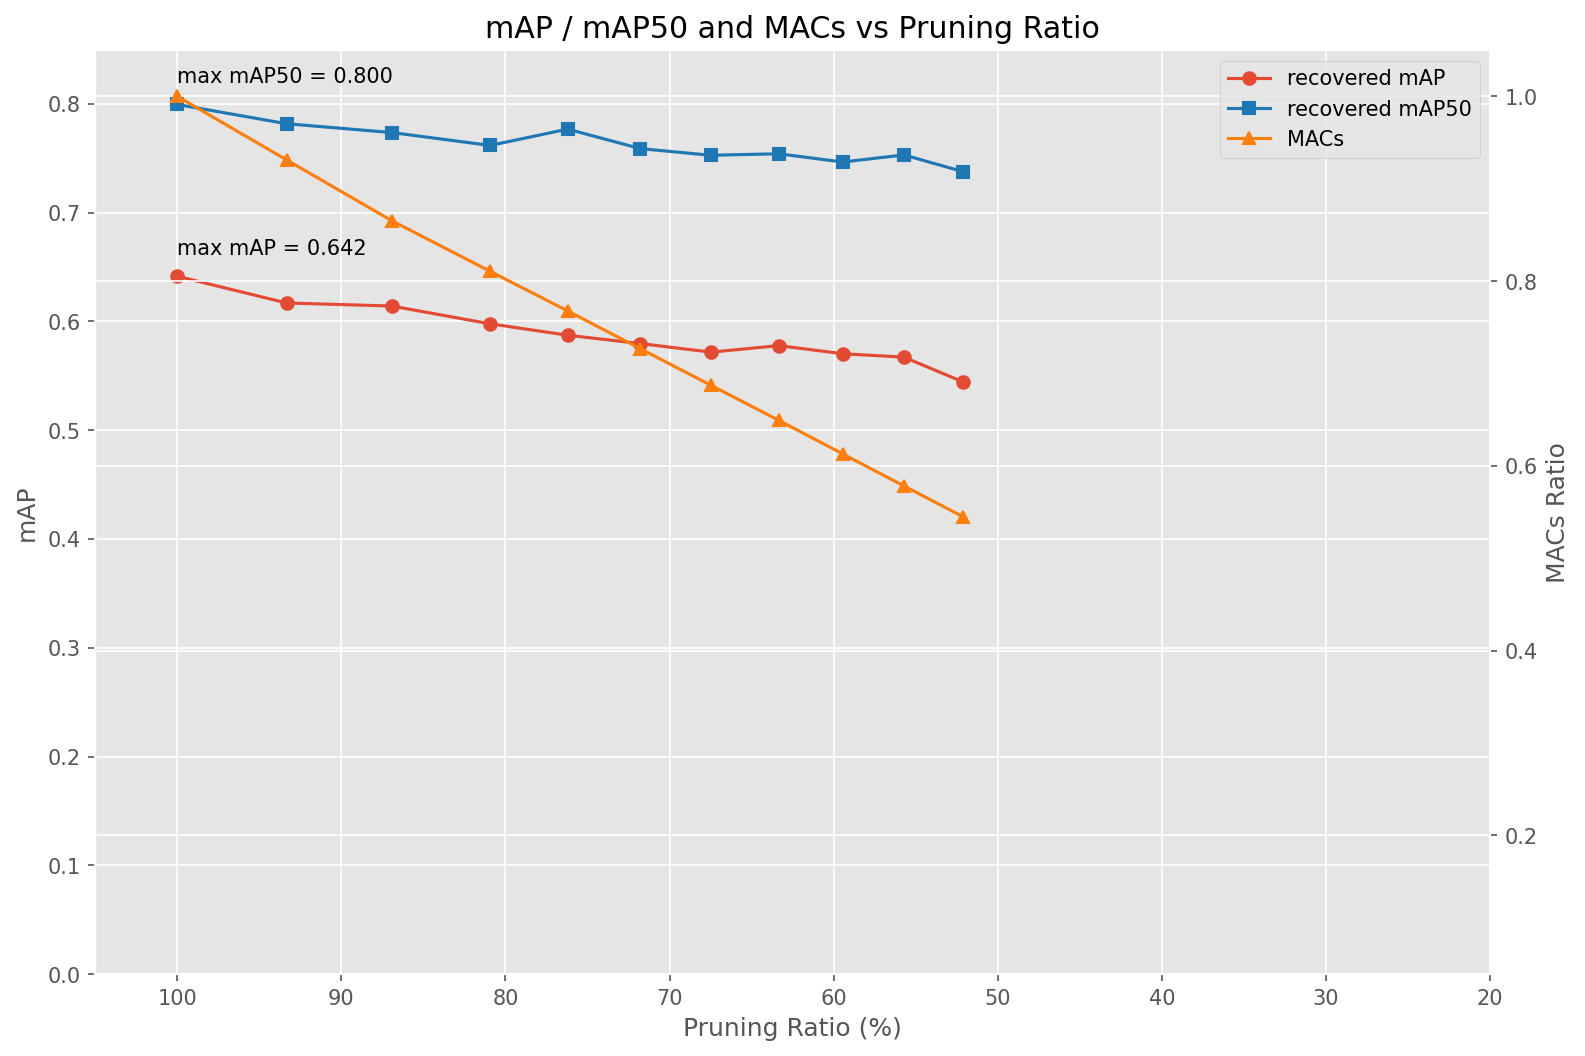

EXPORTING FINAL PRUNED MODEL

🎉 ALL DONE!


In [ ]:
# CONFIGURE THESE 
MODEL_PATH = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt"
DATA_YAML = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml"
ITERATIVE_STEPS = 10
TARGET_PRUNE_RATE = 0.3
MAX_MAP_DROP = 1

# Pruning config
pruning_cfg = {
    'data': DATA_YAML,
    'epochs': 10,  # Fine-tune epochs per iteration
    'batch': 16,
    'imgsz': 640,
    'device': 0 if torch.cuda.is_available() else 'cpu',
    'project': 'YOLO_V8_0.3_prune_ITERATIVE_MAGNITUDE',
    'exist_ok': True,
    'patience': 100,
    'save': True,
    'verbose': True,
    'plots': True,
    'name' : 'ITERATIVE_PRUNNING'
}

# Calculate per-step pruning ratio
pruning_ratio = 1 - math.pow((1 - TARGET_PRUNE_RATE), 1 / ITERATIVE_STEPS)

print("="*70)
print("PRUNING CONFIGURATION")
print("="*70)
print(f"Model: {MODEL_PATH}")
print(f"Data: {DATA_YAML}")
print(f"Iterative steps: {ITERATIVE_STEPS}")
print(f"Target prune rate: {TARGET_PRUNE_RATE*100}%")
print(f"Per-step ratio: {pruning_ratio:.4f} ({pruning_ratio*100:.2f}%)")
print(f"Max mAP drop: {MAX_MAP_DROP}")
print(f"Fine-tune epochs: {pruning_cfg['epochs']}")
print(f"Device: {pruning_cfg['device']}")
print("="*70)
print("="*70)
print("LOADING MODEL")
print("="*70)
model = YOLO(MODEL_PATH)
model.__setattr__("train_v2", train_v2.__get__(model))

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
pruning_cfg['device'] = 0 if device.type == 'cuda' else 'cpu'
model.model.to(device)
model.model.train()

print(f" Model loaded on {device}")

# Replace C2f with C2f_v2
print("\nReplacing C2f with C2f_v2...")
replace_c2f_with_c2f_v2(model.model)
initialize_weights(model.model)
model.model.to(device)

print(" C2f modules replaced with C2f_v2")


for name, param in model.model.named_parameters():
    param.requires_grad = True

example_inputs = torch.randn(1, 3, pruning_cfg["imgsz"], pruning_cfg["imgsz"]).to(device)

model.model = model.model.to(device)
for param in model.model.parameters():
    param.data = param.data.to(device)


base_macs, base_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
print(f"\n📊 Baseline Model:")
print(f"  MACs: {base_macs/1e9:.3f} G")
print(f"  Parameters: {base_nparams:,} ({base_nparams/1e6:.2f} M)")
print("="*70)
print("BASELINE VALIDATION")
print("="*70)

macs_list, nparams_list, map_list, map50_list, pruned_map_list = [], [], [], [], []
pruning_cfg['name'] = f"baseline_val"
pruning_cfg['batch'] = 16
validation_model = deepcopy(model)
metric = validation_model.val(**pruning_cfg)
init_map = metric.box.map
init_map50 = metric.box.map50
macs_list.append(base_macs)
nparams_list.append(100)
map_list.append(init_map)
map50_list.append(init_map50)
pruned_map_list.append(init_map)

print(f"\n✅ Baseline Results:")
print(f"  MACs: {base_macs/1e9:.3f} G")
print(f"  Params: {base_nparams/1e6:.3f} M")
print(f"  mAP50-95: {init_map:.4f}")
print(f"  mAP50: {init_map50:.4f}")
print("\n" + "="*70)
print("⚠️  STARTING ITERATIVE PRUNING")
print("="*70)
print(f"This will take approximately {ITERATIVE_STEPS * pruning_cfg['epochs'] * 10 / 60:.1f} hours")
print(f"{ITERATIVE_STEPS} iterations × {pruning_cfg['epochs']} epochs × ~10 min/epoch")
print("="*70 + "\n")

import time
start_time = time.time()

for i in range(ITERATIVE_STEPS):
    print("\n" + "="*70)
    print(f"ITERATION {i+1}/{ITERATIVE_STEPS}")
    print("="*70)
    
    # Prepare model for pruning
    model.model.train()
    for name, param in model.model.named_parameters():
        param.requires_grad = True

    # Ignore Detect head only
    ignored_layers = []
    for m in model.model.modules():
        if isinstance(m, Detect):
            ignored_layers.append(m)
    
    print(f"Ignoring {len(ignored_layers)} Detect layers")

    # Create pruner
    example_inputs = example_inputs.to(device)
    
    # Ensure model is on correct device
    model.model = model.model.to(device)
    for param in model.model.parameters():
        param.data = param.data.to(device)
    
    pruner = tp.pruner.GroupNormPruner(
        model.model,
        example_inputs,
        importance=tp.importance.GroupMagnitudeImportance(),
        iterative_steps=1,
        pruning_ratio=pruning_ratio,
        ignored_layers=ignored_layers,
    )

  
    print(f"Pruning {pruning_ratio*100:.2f}% of channels...")
    pruner.step()
    pruning_cfg['name'] = f"step_{i}_pre_val"
    pruning_cfg['batch'] = 16
    validation_model.model = deepcopy(model.model)
    metric = validation_model.val(**pruning_cfg)
    pruned_map = metric.box.map
    pruned_macs, pruned_nparams = tp.utils.count_ops_and_params(pruner.model, example_inputs)
    current_speed_up = float(macs_list[0]) / pruned_macs
    
    print(f"\n After Pruning:")
    print(f"  MACs: {pruned_macs/1e9:.3f} G (speedup: {current_speed_up:.2f}x)")
    print(f"  Params: {pruned_nparams/1e6:.3f} M ({pruned_nparams/base_nparams*100:.1f}% remaining)")
    print(f"  mAP (before fine-tune): {pruned_map:.4f}")
    print(f"\n🔧 Fine-tuning for {pruning_cfg['epochs']} epochs...")
    for name, param in model.model.named_parameters():
        param.requires_grad = True
    
    pruning_cfg['name'] = f"step_{i}_finetune"
    pruning_cfg['batch'] = 16
    model.train_v2(pruning=True, **pruning_cfg)
    pruning_cfg['name'] = f"step_{i}_post_val"
    pruning_cfg['batch'] = 16
    validation_model = YOLO(model.trainer.best)
    metric = validation_model.val(**pruning_cfg)
    current_map = metric.box.map
    current_map50 = metric.box.map50
    
    print(f"\n After Fine-tuning:")
    print(f"  mAP50-95: {current_map:.4f}")
    print(f"  mAP50: {current_map50:.4f}")
    print(f"  mAP recovery: {(current_map - pruned_map)*100:+.2f}%")

    macs_list.append(pruned_macs)
    nparams_list.append(pruned_nparams / base_nparams * 100)
    map_list.append(current_map)
    map50_list.append(current_map50)

    save_pruning_performance_graph(nparams_list, map_list, map50_list, macs_list, "L2 norm")

    del pruner
    
    if init_map - current_map > MAX_MAP_DROP:
        print(f"\n⚠️  Early stopping! mAP drop ({init_map - current_map:.4f}) exceeds threshold ({MAX_MAP_DROP})")
        break
    
    elapsed = time.time() - start_time
    remaining = (elapsed / (i + 1)) * (ITERATIVE_STEPS - i - 1)
    print(f"\n⏱️  Elapsed: {elapsed/3600:.1f}h, Estimated remaining: {remaining/3600:.1f}h")

print("\n" + "="*70)
print("✅ PRUNING COMPLETE!")
print("="*70)
total_time = time.time() - start_time
print(f"Total time: {total_time/3600:.2f} hours")
print("="*70)
print("FINAL PRUNING RESULTS")
print("="*70)

print("\nPruning Progression:")
print(f"{'Step':<6} {'Params %':<12} {'mAP50-95':<12} {'mAP50':<12}")
print("-" * 45)
for i, (params, map_val, map50_val) in enumerate(zip(nparams_list, map_list, map50_list)):
    print(f"{i:<6} {params:<12.1f} {map_val:<12.4f} {map50_val:<12.4f}")

best_idx = np.argmax(map_list)
print(f"\n🏆 Best Result:")
print(f"  Step: {best_idx}")
print(f"  Params: {nparams_list[best_idx]:.1f}% ({base_nparams * nparams_list[best_idx]/100 / 1e6:.2f}M)")
print(f"  mAP50-95: {map_list[best_idx]:.4f}")
print(f"  mAP50: {map50_list[best_idx]:.4f}")

print(f"\n📊 Final Result:")
print(f"  Params: {nparams_list[-1]:.1f}% ({base_nparams * nparams_list[-1]/100 / 1e6:.2f}M)")
print(f"  mAP50-95: {map_list[-1]:.4f}")
print(f"  mAP50: {map50_list[-1]:.4f}")
print(f"  Total reduction: {100 - nparams_list[-1]:.1f}%")
print(f"  mAP loss: {(init_map - map_list[-1])*100:.2f}%")
print("="*70)
print("EXPORTING FINAL PRUNED MODEL")
print("="*70)

# Find the best model from last iteration
prune_dir = Path("runs/prune")
experiments = list(prune_dir.glob("step_*_finetune"))

if experiments:
    last_step = max(experiments, key=lambda x: int(x.name.split('_')[1]))
    best_weight = last_step / "weights" / "best.pt"
    
    if best_weight.exists():
        print(f"\n✅ Loading: {best_weight}")
        
        final_model = YOLO(str(best_weight))
        
        # Export to ONNX
        print("\nExporting to ONNX...")
        onnx_path = final_model.export(
            format='onnx',
            imgsz=640,
            simplify=True
        )
        
        print(f"\n✅ ONNX exported: {onnx_path}")
        print(f"File size: {Path(onnx_path).stat().st_size / 1e6:.2f} MB")
        
print("\n🎉 ALL DONE!")

ONE SHOT BN

In [ ]:
import math
import time
from copy import deepcopy
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch_pruning as tp

from ultralytics import YOLO
from ultralytics.nn.modules import Detect

# -----------------------------
# Helpers
# -----------------------------
def torch_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

def get_detect_ignored_submodules(yolo_nn: nn.Module):
    """
    For YOLOv8, do NOT ignore the whole Detect module.
    Ignore only final prediction submodules inside Detect to keep output shapes stable.
    """
    detect = None
    for m in yolo_nn.modules():
        if isinstance(m, Detect):
            detect = m
            break

    ignored = []
    if detect is not None:
        for attr in ["cv2", "cv3", "dfl"]:
            if hasattr(detect, attr):
                mod = getattr(detect, attr)
                if isinstance(mod, (list, nn.ModuleList)):
                    ignored += list(mod)
                else:
                    ignored.append(mod)
    return detect, ignored

def de_inference_parameters(model: nn.Module):
    """
    PyTorch 2.x fix: after pruning, some params can become "inference tensors".
    Ultralytics tries to set requires_grad=True and crashes.
    This converts inference tensors back to normal nn.Parameter.
    """
    for module in model.modules():
        for name, p in list(module._parameters.items()):
            if p is None:
                continue
            if hasattr(torch, "is_inference") and torch.is_inference(p):
                module._parameters[name] = nn.Parameter(p.detach().clone(), requires_grad=True)
            else:
                p.requires_grad_(True)

def load_best_into_current_pruned_model(yolo: YOLO, best_path: str, device: torch.device):
    """
    Load best.pt weights INTO the CURRENT (already pruned) yolo.model.
    Avoids YOLO(best.pt) which can rebuild a fresh unpruned architecture.
    """
    ckpt = torch.load(best_path, map_location="cpu")

    state = None
    if isinstance(ckpt, dict):
        if "ema" in ckpt and ckpt["ema"] is not None:
            state = ckpt["ema"].state_dict()
        elif "model" in ckpt and ckpt["model"] is not None:
            m = ckpt["model"]
            state = m.state_dict() if hasattr(m, "state_dict") else m
        elif "state_dict" in ckpt:
            state = ckpt["state_dict"]
    elif hasattr(ckpt, "state_dict"):
        state = ckpt.state_dict()

    if state is None:
        raise RuntimeError(f"Could not extract state_dict from: {best_path}")

    missing, unexpected = yolo.model.load_state_dict(state, strict=False)
    yolo.model.to(device).train()

    de_inference_parameters(yolo.model)

    print(f"✅ Loaded best weights into PRUNED model: {best_path}")
    print(f"   Missing keys: {len(missing)} | Unexpected keys: {len(unexpected)}")


# ========================================
# CELL 5: Configuration
# ========================================
MODEL_PATH = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt"
DATA_YAML  = r"C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml"

ITERATIVE_STEPS   = 1
TARGET_PRUNE_RATE = 0.95
MAX_MAP_DROP      = 1.0

pruning_cfg = {
    "data": DATA_YAML,
    "epochs": 100,  
    "batch": 16,
    "imgsz": 640,
    "device": 0 if torch.cuda.is_available() else "cpu",
    "project": "YOLO_V8_BN_0.95",
    "exist_ok": True,
    "patience": 100,
    "save": True,
    "verbose": True,
    "plots": True,
    "name": "ONESHOT_PRUNING",
}


# after S steps: remaining = (1-r)^S = (1-T)
pruning_ratio = 1 - (1 - TARGET_PRUNE_RATE) ** (1 / ITERATIVE_STEPS)

print("=" * 70)
print("PRUNING CONFIGURATION")
print("=" * 70)
print(f"Model: {MODEL_PATH}")
print(f"Data: {DATA_YAML}")
print(f"Iterative steps: {ITERATIVE_STEPS}")
print(f"Target prune rate: {TARGET_PRUNE_RATE*100:.1f}%")
print(f"Per-step ratio: {pruning_ratio:.4f} ({pruning_ratio*100:.2f}%)")
print(f"Max mAP drop: {MAX_MAP_DROP}")
print(f"Fine-tune epochs: {pruning_cfg['epochs']}")
print(f"Device: {pruning_cfg['device']}")
print("=" * 70)

assert Path(MODEL_PATH).exists(), f"❌ Model not found: {MODEL_PATH}"
assert Path(DATA_YAML).exists(), f"❌ Data YAML not found: {DATA_YAML}"
print("✅ Model found")
print("✅ Data YAML found")
print("=" * 70)
print("LOADING MODEL")
print("=" * 70)

model = YOLO(MODEL_PATH)
model.__setattr__("train_v2", train_v2.__get__(model))

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
pruning_cfg["device"] = 0 if device.type == "cuda" else "cpu"

model.model.to(device).train()
de_inference_parameters(model.model)
print(f"✅ Model loaded on {device}")

print("\nReplacing C2f with C2f_v2...")
replace_c2f_with_c2f_v2(model.model)
initialize_weights(model.model)
model.model.to(device).train()
de_inference_parameters(model.model)
print("✅ C2f modules replaced with C2f_v2")

example_inputs = torch.randn(1, 3, pruning_cfg["imgsz"], pruning_cfg["imgsz"]).to(device)

base_macs, base_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
print("\n Baseline Model:")
print(f"  MACs: {base_macs/1e9:.3f} G")
print(f"  Params(tp): {base_nparams/1e6:.3f} M")
print(f"  Params(torch): {torch_params(model.model)/1e6:.3f} M")
print("=" * 70)
print("BASELINE VALIDATION")
print("=" * 70)

macs_list, nparams_list, map_list, map50_list = [], [], [], []

pruning_cfg["name"] = "baseline_val"
pruning_cfg["batch"] = 16

validation_model = deepcopy(model)
metric = validation_model.val(**pruning_cfg)
init_map = float(metric.box.map)
init_map50 = float(metric.box.map50)

macs_list.append(float(base_macs))
nparams_list.append(100.0)
map_list.append(init_map)
map50_list.append(init_map50)

print("\n✅ Baseline Results:")
print(f"  mAP50-95: {init_map:.4f}")
print(f"  mAP50:    {init_map50:.4f}")
print("\n" + "=" * 70)
print("  STARTING ITERATIVE PRUNING")
print("=" * 70)
print(f"{ITERATIVE_STEPS} iterations × {pruning_cfg['epochs']} epochs")
print("=" * 70 + "\n")

start_time = time.time()

for i in range(ITERATIVE_STEPS):
    print("\n" + "=" * 70)
    print(f"ITERATION {i+1}/{ITERATIVE_STEPS}")
    print("=" * 70)

    model.model.to(device).train()
    de_inference_parameters(model.model)
    detect, ignored_layers = get_detect_ignored_submodules(model.model)
    print(f"Detect found: {detect is not None} | Ignored submodules: {len(ignored_layers)}")

    pruner = tp.pruner.BNScalePruner(
        model.model,
        example_inputs,
        importance=tp.importance.BNScaleImportance(),
        pruning_ratio=pruning_ratio,
        ignored_layers=ignored_layers,
        global_pruning=True,
    )

    before = torch_params(model.model)
    print(f"Pruning {pruning_ratio*100:.2f}% of channels (this step)...")
    with torch.inference_mode(False):
        pruner.step()

    de_inference_parameters(model.model)

    after = torch_params(model.model)
    print(f"torch params: {before/1e6:.3f}M -> {after/1e6:.3f}M (delta {(before-after)/1e6:.3f}M)")

    pruning_cfg["name"] = f"step_{i}_pre_val"
    metric = model.val(**pruning_cfg)
    pruned_map = float(metric.box.map)
    pruned_macs, pruned_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
    speedup = float(base_macs) / float(pruned_macs)

    print("\n After Pruning:")
    print(f"  MACs: {pruned_macs/1e9:.3f} G (speedup: {speedup:.2f}x)")
    print(f"  Params: {pruned_nparams/1e6:.3f} M ({(pruned_nparams/base_nparams)*100:.1f}% remaining)")
    print(f"  mAP50-95 (pre-FT): {pruned_map:.4f}")
    print(f"\n🔧 Fine-tuning for {pruning_cfg['epochs']} epochs...")
    pruning_cfg["name"] = f"step_{i}_finetune"

    de_inference_parameters(model.model)

    model.train_v2(pruning=True, **pruning_cfg)
    best_path = model.trainer.best
    load_best_into_current_pruned_model(model, best_path, device)
    pruning_cfg["name"] = f"step_{i}_post_val"
    metric = model.val(**pruning_cfg)
    current_map = float(metric.box.map)
    current_map50 = float(metric.box.map50)

    post_macs, post_nparams = tp.utils.count_ops_and_params(model.model, example_inputs)
    post_speedup = float(base_macs) / float(post_macs)

    print("\n After Fine-tuning:")
    print(f"  Params(tp): {post_nparams/1e6:.3f} M ({(post_nparams/base_nparams)*100:.1f}% remaining)")
    print(f"  MACs: {post_macs/1e9:.3f} G (speedup: {post_speedup:.2f}x)")
    print(f"  mAP50-95: {current_map:.4f}")
    print(f"  mAP50:    {current_map50:.4f}")
    print(f"  mAP recovery: {(current_map - pruned_map)*100:+.2f}%")
    print(f"  POST-FT torch params: {torch_params(model.model)/1e6:.3f} M")

    macs_list.append(float(post_macs))
    nparams_list.append(float(post_nparams / base_nparams * 100))
    map_list.append(current_map)
    map50_list.append(current_map50)

    save_pruning_performance_graph(nparams_list, map_list, map50_list, macs_list, "BNScale")

    if (init_map - current_map) > MAX_MAP_DROP:
        print(f"\n⚠️ Early stopping! mAP drop ({init_map - current_map:.4f}) exceeds threshold ({MAX_MAP_DROP})")
        break

    elapsed = time.time() - start_time
    remaining = (elapsed / (i + 1)) * (ITERATIVE_STEPS - i - 1)
    print(f"\n⏱️  Elapsed: {elapsed/3600:.2f}h, Estimated remaining: {remaining/3600:.2f}h")

print("\n" + "=" * 70)
print("✅ PRUNING COMPLETE!")
print("=" * 70)
total_time = time.time() - start_time
print(f"Total time: {total_time/3600:.2f} hours")
print("=" * 70)
print("FINAL PRUNING RESULTS")
print("=" * 70)

print("\nPruning Progression:")
print(f"{'Step':<6} {'Params %':<12} {'mAP50-95':<12} {'mAP50':<12}")
print("-" * 45)
for idx, (params_pct, map_val, map50_val) in enumerate(zip(nparams_list, map_list, map50_list)):
    print(f"{idx:<6} {params_pct:<12.1f} {map_val:<12.4f} {map50_val:<12.4f}")

best_idx = int(np.argmax(map_list))
print(f"\n🏆 Best Result:")
print(f"  Step: {best_idx}")
print(f"  Params: {nparams_list[best_idx]:.1f}% ({base_nparams*nparams_list[best_idx]/100/1e6:.2f}M)")
print(f"  mAP50-95: {map_list[best_idx]:.4f}")
print(f"  mAP50:    {map50_list[best_idx]:.4f}")

print(f"\n📊 Final Result:")
print(f"  Params: {nparams_list[-1]:.1f}% ({base_nparams*nparams_list[-1]/100/1e6:.2f}M)")
print(f"  mAP50-95: {map_list[-1]:.4f}")
print(f"  mAP50:    {map50_list[-1]:.4f}")
print(f"  Total reduction: {100 - nparams_list[-1]:.1f}%")
print(f"  mAP loss: {(init_map - map_list[-1])*100:.2f}%")
print("=" * 70)
print("EXPORTING FINAL PRUNED MODEL")
print("=" * 70)

try:
    best_path = model.trainer.best
    load_best_into_current_pruned_model(model, best_path, device)

    print("\nExporting to ONNX...")
    onnx_path = model.export(format="onnx", imgsz=pruning_cfg["imgsz"], simplify=True)
    print(f"\n✅ ONNX exported: {onnx_path}")
    print(f"File size: {Path(onnx_path).stat().st_size / 1e6:.2f} MB")
except Exception as e:
    print(f"❌ Export failed: {e}")

print("\n🎉 ALL DONE!")


PRUNING CONFIGURATION
Model: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\Models\CombinedDS\YOLOV8N\weights\best.pt
Data: C:\Users\alijo\OneDrive\Desktop\BachelorThesis\BachelorThesis\MixedDS.yaml
Iterative steps: 1
Target prune rate: 95.0%
Per-step ratio: 0.9500 (95.00%)
Max mAP drop: 1.0
Fine-tune epochs: 100
Device: 0
✅ Model found
✅ Data YAML found
LOADING MODEL
✅ Model loaded on cuda:0

Replacing C2f with C2f_v2...
✅ C2f modules replaced with C2f_v2

📊 Baseline Model:
  MACs: 4.071 G
  Params(tp): 3.011 M
  Params(torch): 3.011 M
BASELINE VALIDATION
Ultralytics 8.3.223  Python-3.10.11 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
Model summary (fused): 81 layers, 3,005,843 parameters, 12,691 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.20.1 ms, read: 37.411.6 MB/s, size: 50.6 KB)
val: Scanning C:\Users\alijo\OneDrive\Desktop\LeafminerOnly\val\labels.cache... 314 images, 106 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 314/314 78.5Ki

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x000001FEC0DB96C0>
Traceback (most recent call last):
  File "c:\Users\alijo\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\utils\data\dataloader.py", line 1618, in __del__
    self._shutdown_workers()
  File "c:\Users\alijo\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\utils\data\dataloader.py", line 1576, in _shutdown_workers
    if self._persistent_workers or self._workers_status[worker_id]:
AttributeError: '_MultiProcessingDataLoaderIter' object has no attribute '_workers_status'


KeyboardInterrupt: 